# Mental health risk prediction Project

## 1. Setup and Data Loading 

In [8]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import train_test_split

root = Path.cwd().parents[0]

data_path = root / "data" / "student_mental_health.csv"

df = pd.read_csv(data_path)

## 2. Dataset Structure

In [9]:
print("Shape:")
print(df.shape)

print("\n Data Types:")
print(df.dtypes)

df.info()

Shape:
(2000, 17)

 Data Types:
Student_ID                            str
Age                                 int64
Gender                                str
Year_of_Study                       int64
Sleep_Hours                       float64
Study_Hours_Per_Week              float64
GPA                               float64
Social_Media_Hours                float64
Screen_Time_Hours                 float64
Physical_Activity                     str
Financial_Stress                  float64
Family_Support                    float64
Attendance_Rate                   float64
Part_Time_Job                         str
Diet_Quality                          str
Previous_Mental_Health_History        str
Mental_Health_Risk                    str
dtype: object
<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Student_ID       

## 3. Statistical Description

In [ ]:
print("\n Numeric summary:")
df.describe(include="number").T

# print("\n Categorical summary")
# df.describe(include="object")




 Numeric summary:


Mental_Health_Risk,High,Low,Medium
Gender,,,
Female,34.60,33.47,31.93
Male,33.37,31.76,34.87
Non-binary,34.02,40.21,25.77


## 4. Missing Values

In [4]:
missing = df.isnull().sum()

missing_pct = df.isnull().mean() * 100

missing_df = pd.DataFrame({"Count": missing, "Percent": missing_pct})

display(missing_df[missing_df["Count"] > 0].sort_values("Percent", ascending=False))

,Count,Percent
Financial_Stress,91,4.55
Diet_Quality,69,3.45
Sleep_Hours,62,3.10
Social_Media_Hours,58,2.90
Family_Support,54,2.70
Attendance_Rate,47,2.35
GPA,38,1.90


## 5. Duplicates and Repeated


In [5]:
print("Exact duplicate rows:",df.duplicated().sum())
print("Repeated student IDs",df["Student_ID"].duplicated().sum())

Exact duplicate rows: 0
Repeated student IDs 0


## 6. Checks

In [17]:
for column in df.select_dtypes(include="object").columns:
    if column != "Student_ID":
        print(f"\n{column}")
        print(df[column].value_counts(dropna=False))

checks = {
    "Sleep outside 0–24 hours": ~df["Sleep_Hours"].between(0, 24)
    & df["Sleep_Hours"].notna(),
    "GPA outside 0–4": ~df["GPA"].between(0, 4) & df["GPA"].notna(),
    "Attendance outside 0–100": ~df["Attendance_Rate"].between(0, 100)
    & df["Attendance_Rate"].notna(),
    "Financial stress outside 1–10": ~df["Financial_Stress"].between(1, 10)
    & df["Financial_Stress"].notna(),
    "Family support outside 1–10": ~df["Family_Support"].between(1, 10)
    & df["Family_Support"].notna(),
}

for name, condition in checks.items():
    print(name, ":", condition.sum())


inconsistent_screen_time = df["Social_Media_Hours"] > df["Screen_Time_Hours"]

display(
    df.loc[
        inconsistent_screen_time,
        ["Student_ID", "Social_Media_Hours", "Screen_Time_Hours"],
    ]
)


Gender
Gender
Female        971
Male          932
Non-binary     97
Name: count, dtype: int64

Physical_Activity
Physical_Activity
Moderate    906
Low         679
High        415
Name: count, dtype: int64

Part_Time_Job
Part_Time_Job
No     1289
Yes     711
Name: count, dtype: int64

Diet_Quality
Diet_Quality
Average    860
Poor       587
Good       484
NaN         69
Name: count, dtype: int64

Previous_Mental_Health_History
Previous_Mental_Health_History
No     1408
Yes     592
Name: count, dtype: int64

Mental_Health_Risk
Mental_Health_Risk
High      680
Medium    660
Low       660
Name: count, dtype: int64
Sleep outside 0–24 hours : 0
GPA outside 0–4 : 0
Attendance outside 0–100 : 0
Financial stress outside 1–10 : 0
Family support outside 1–10 : 0


/tmp/ipykernel_15492/1557371905.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for column in df.select_dtypes(include="object").columns:


,Student_ID,Social_Media_Hours,Screen_Time_Hours
78,STU0079,5.0,4.9
168,STU0169,5.6,5.3
209,STU0210,7.5,7.3
278,STU0279,6.0,5.1
382,STU0383,5.3,4.1
424,STU0425,5.5,4.4
476,STU0477,5.5,5.3
505,STU0506,5.6,5.5
557,STU0558,4.6,4.4
588,STU0589,5.7,5.3


## 7. Target distribution

,Count,Percent
Mental_Health_Risk,,
Low,660,33.0
Medium,660,33.0
High,680,34.0


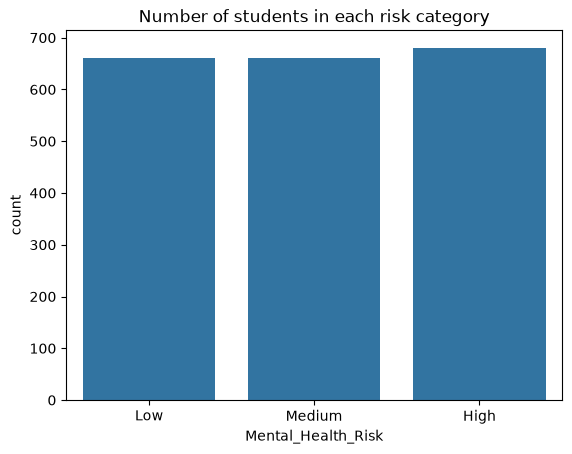

In [7]:
target = "Mental_Health_Risk"
risk_order = ["Low", "Medium", "High"]

target_summary = pd.DataFrame(
    {
        "Count": df[target].value_counts(),
        "Percent": df[target].value_counts(normalize=True) * 100,
    }
).reindex(risk_order)

display(target_summary)

sns.countplot(data=df, x=target, order=risk_order)
plt.title("Number of students in each risk category")
plt.show()

## 8. Boxplots

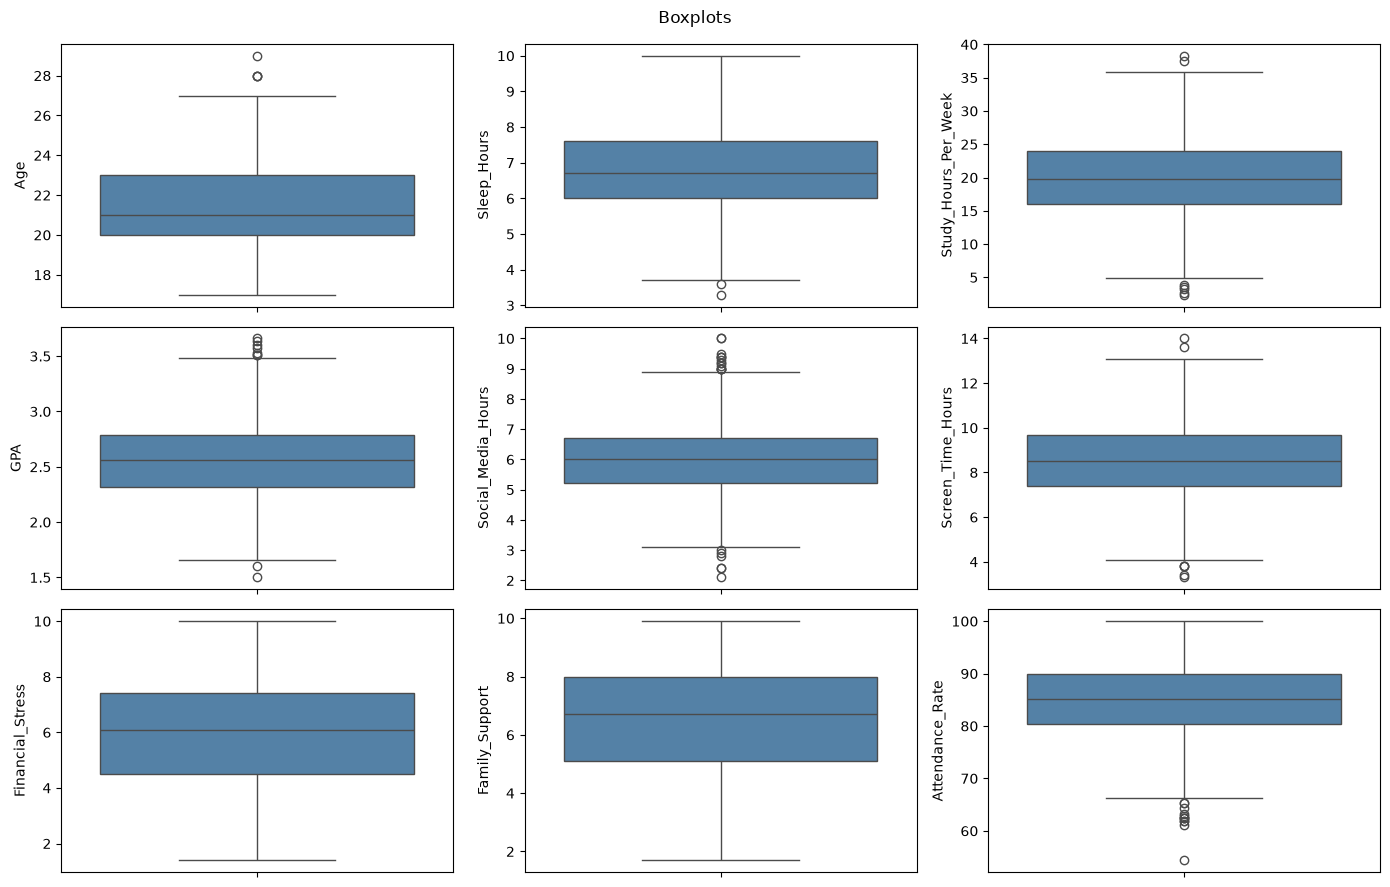

In [15]:
numeric_cols = [
    "Age",
    "Sleep_Hours",
    "Study_Hours_Per_Week",
    "GPA",
    "Social_Media_Hours",
    "Screen_Time_Hours",
    "Financial_Stress",
    "Family_Support",
    "Attendance_Rate",
    "Year_of_Study",
    "target_encoded",
]

fig, axes = plt.subplots(3, 3, figsize=(14, 9))
for ax, col in zip(axes.flat, numeric_cols):
    sns.boxplot(data=df, y=col, ax=ax, color="steelblue")
    ax.set_xlabel("")
fig.suptitle("Boxplots")
plt.tight_layout()
plt.show()

## 9. Distributions

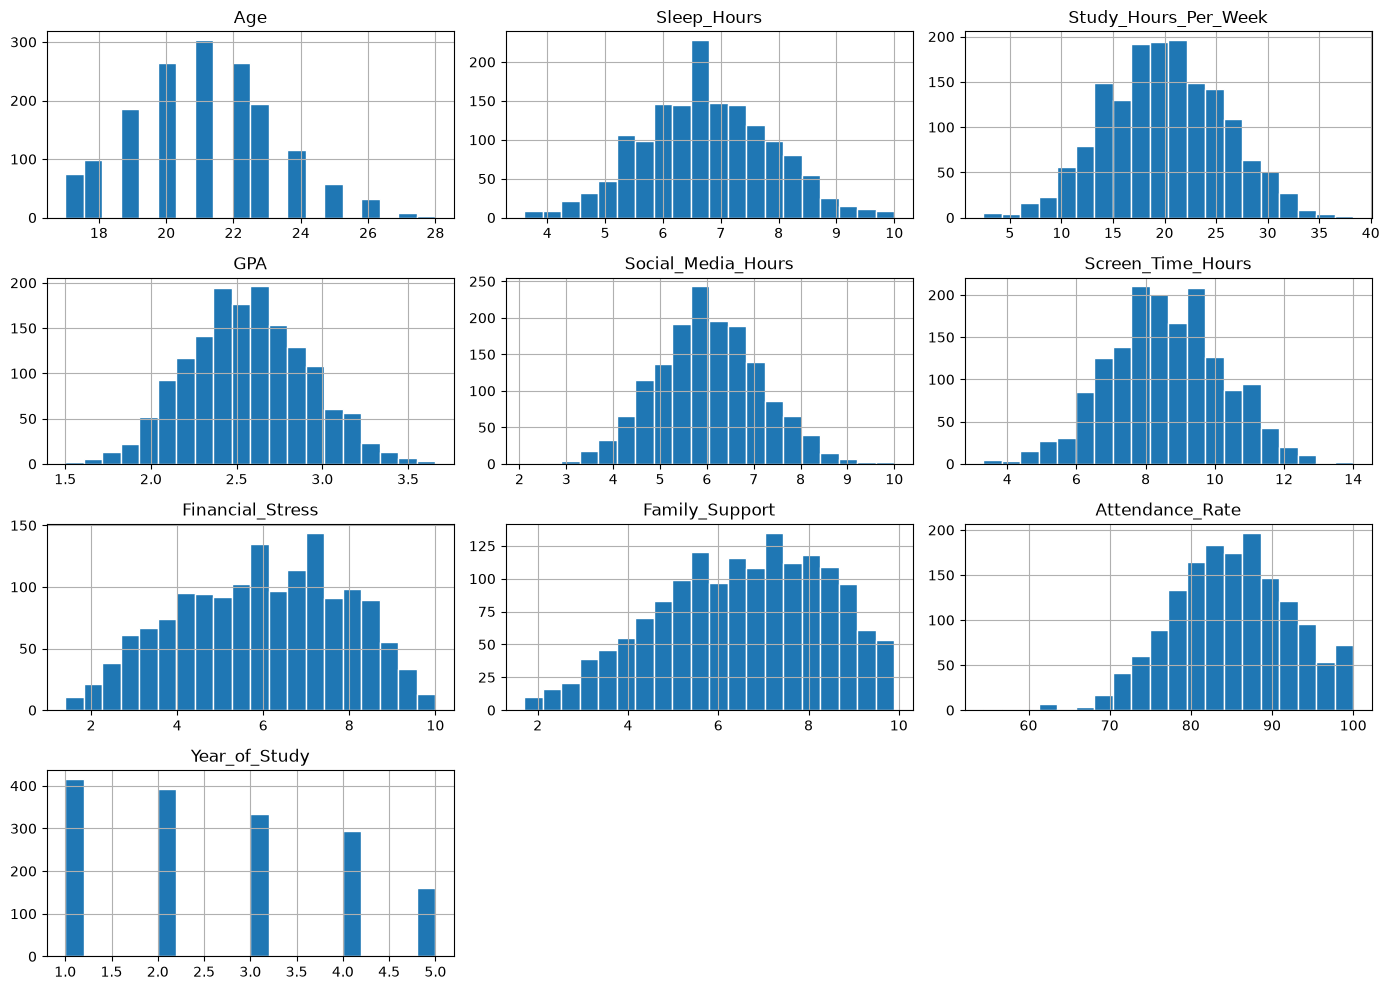

In [14]:
train_df, test_df = train_test_split(
    df, test_size=0.20, random_state=42, stratify=df[target]
)

eda = train_df.copy()

eda[numeric_cols].hist(figsize=(14, 10), bins=20, edgecolor="white")

plt.tight_layout()
plt.show()

## 10. Correlations

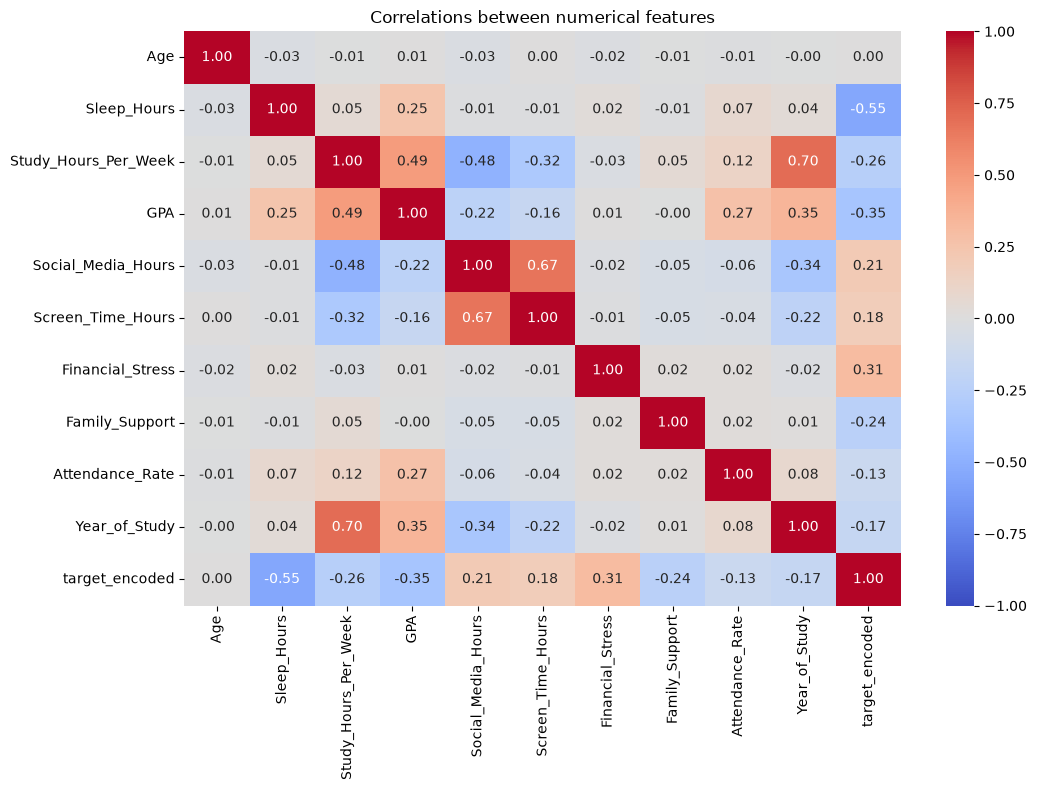

In [ ]:
mapping = {
    'Low':0,
    'Medium':1,
    'High':2
}
eda['target_encoded'] = eda["Mental_Health_Risk"].map(mapping)

correlation = eda[numeric_cols].corr(method='spearman')

plt.figure(figsize=(11, 8))

sns.heatmap(
    correlation, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1
)

plt.title("Correlations between numerical features")
plt.tight_layout()
plt.show()